# Store Sales 시계열 예측
## 1일차: 데이터 이해

### 문제 정의
- 예측 대상: 날짜·매장(store_nbr)·상품군(family)별 판매량(sales)
- 평가 지표: RMSLE (낮을수록 좋음)
- 제출 형식: `id,sales` (헤더 포함), 노트북 출력으로 submission.csv 생성

### 대회 확인 메모 (2026-10-13 확인)
- 제출 제한: 하루 5회, 최종 선택 2개
- 리더보드: test 전체로 채점, 3개월 지난 제출은 무효 → 순위 기록 시 날짜 필수
- sales는 소수 가능 → 정수 반올림 금지
- onpromotion은 프로모션 중인 상품 개수 (0/1 아님)
- 휴일: transferred, Transfer, Bridge, Work Day, Additional 구분 필요
- 참고: 급여일(15일·말일), 2016-04-16 지진

### 코드로 확인할 것
- [x] test 기간: 2017-08-16 ~ 2017-08-31, **16일** (설명의 "15 days"와 다름) / 54매장 × 33상품군
- [x] train 날짜 범위: 2013-01-01 ~ 2017-08-15 (test 직전까지 연속)
  - 달력 1688일 중 1684일만 존재 → **매년 12-25 (2013~2016) 4일 누락** (휴무 추정, 0으로 채우지 않음)
  - 존재하는 날짜에서는 54 × 33 조합이 모두 있음 (3,000,888행)
- [x] 결측치·중복: train/test 모두 결측치 0, id 중복 0, 날짜·매장·상품군 중복 0
- [x] 판매량 0: 전체 31.3% (939,130행)
  - 전 기간 판매 0인 매장·상품군 조합 53개 (BOOKS 28, BABY CARE 12, LADIESWEAR 10, LAWN AND GARDEN 3) → 0의 약 9.5%만 설명
  - 나머지 0은 판매 시작 시점 차이(가설) 등 → 2일차에 시간 추이로 확인
- [x] transactions: 2013-01-01 ~ 2017-08-15, **test 기간 값 없음 → 미래 정보** (직접 변수로 사용 불가)
  - 83,488행 (날짜 × 매장 기준 90,936 중 7,448개 기록 없음, 원인 미확인)

In [1]:
import os  # 파일·폴더를 다루는 파이썬 기본 모듈

DATA_ROOT = "/kaggle/input"  # 캐글이 데이터를 연결해 두는 최상위 폴더 (str)

# DATA_ROOT 아래 모든 폴더를 방문하며 파일 크기와 경로를 출력
for dirpath, dirnames, filenames in os.walk(DATA_ROOT):
    for filename in sorted(filenames):                  # 파일 이름을 알파벳순으로 정렬
        full_path = os.path.join(dirpath, filename)     # "폴더경로/파일이름" 만들기
        size_mb = os.path.getsize(full_path) / 1024**2  # 바이트 → MB
        print(f"{size_mb:8.2f} MB   {full_path}")

    0.02 MB   /kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv
    0.02 MB   /kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv
    0.33 MB   /kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv
    0.00 MB   /kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv
    0.97 MB   /kaggle/input/competitions/store-sales-time-series-forecasting/test.csv
  116.16 MB   /kaggle/input/competitions/store-sales-time-series-forecasting/train.csv
    1.48 MB   /kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv


In [2]:
import pandas as pd  # 표 데이터를 다루는 라이브러리, 관례적으로 pd라는 별명 사용

# 위 출력에서 확인한 실제 데이터 폴더 경로
DATA_DIR = "/kaggle/input/competitions/store-sales-time-series-forecasting"

# CSV 파일을 읽어 DataFrame으로 만든다. date 열은 날짜 자료형으로 변환
train = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=["date"])
test = pd.read_csv(f"{DATA_DIR}/test.csv", parse_dates=["date"])

# (행 수, 열 수) 출력
print("train shape:", train.shape)
print("test  shape:", test.shape)

train shape: (3000888, 6)
test  shape: (28512, 5)


In [3]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [4]:
# test의 날짜 범위와 고유값 개수 확인
print("test 시작일:", test["date"].min())
print("test 종료일:", test["date"].max())
print("test 날짜 수:", test["date"].nunique())
print("매장 수:", test["store_nbr"].nunique())
print("상품군 수:", test["family"].nunique())

# 날짜 × 매장 × 상품군 = 행 수인지 확인
expected_rows = test["date"].nunique() * test["store_nbr"].nunique() * test["family"].nunique()
print("곱한 값:", expected_rows, "/ 실제 행 수:", len(test))

test.head()  # 셀의 마지막 줄은 print 없이도 결과가 표로 표시됨

test 시작일: 2017-08-16 00:00:00
test 종료일: 2017-08-31 00:00:00
test 날짜 수: 16
매장 수: 54
상품군 수: 33
곱한 값: 28512 / 실제 행 수: 28512


,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [5]:
train_start = train["date"].min()                    # 가장 이른 날짜
train_end = train["date"].max()                      # 가장 늦은 날짜
calendar_days = (train_end - train_start).days + 1   # 달력상 전체 일수 (양 끝 포함)

print("train 시작일:", train_start)
print("train 종료일:", train_end)
print("달력상 일수:", calendar_days)
print("실제 날짜 수:", train["date"].nunique())
print("매장 수:", train["store_nbr"].nunique())
print("상품군 수:", train["family"].nunique())

expected_rows = train["date"].nunique() * train["store_nbr"].nunique() * train["family"].nunique()
print("곱한 값:", expected_rows, "/ 실제 행 수:", len(train))

train.head()

train 시작일: 2013-01-01 00:00:00
train 종료일: 2017-08-15 00:00:00
달력상 일수: 1688
실제 날짜 수: 1684
매장 수: 54
상품군 수: 33
곱한 값: 3000888 / 실제 행 수: 3000888


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [6]:
# 1) 시작일부터 종료일까지 하루 간격으로 "있어야 할 모든 날짜" 생성
full_dates = pd.date_range(start=train_start, end=train_end, freq="D")

# 2) train에 "실제로 있는 날짜" (중복 제거)
train_dates = pd.DatetimeIndex(train["date"].unique())

# 3) 있어야 할 날짜 − 실제 있는 날짜 = 빠진 날짜
missing_dates = full_dates.difference(train_dates)

print("전체 날짜 수:", len(full_dates))
print("실제 날짜 수:", len(train_dates))
print("빠진 날짜 수:", len(missing_dates))
print(missing_dates)

전체 날짜 수: 1688
실제 날짜 수: 1684
빠진 날짜 수: 4
DatetimeIndex(['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25'], dtype='datetime64[ns]', freq=None)


In [7]:
key_cols = ["date", "store_nbr", "family"]  # 한 행을 구분하는 기준 열

for name, df in [("train", train), ("test", test)]:
    print(f"===== {name} =====")
    print("열별 결측치 개수:")
    print(df.isna().sum())
    print("id 중복 행 수:", df["id"].duplicated().sum())
    print("날짜·매장·상품군 중복 행 수:", df.duplicated(subset=key_cols).sum())
    print()

===== train =====
열별 결측치 개수:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
id 중복 행 수: 0
날짜·매장·상품군 중복 행 수: 0

===== test =====
열별 결측치 개수:
id             0
date           0
store_nbr      0
family         0
onpromotion    0
dtype: int64
id 중복 행 수: 0
날짜·매장·상품군 중복 행 수: 0



In [8]:
# 각 행이 판매량 0인지 표시 (True/False)
is_zero = train["sales"] == 0

print("판매량 0인 행 수:", is_zero.sum())
print(f"전체 대비 비율: {is_zero.mean():.1%}")

# 상품군별 판매량 0 비율 (높은 순)
zero_ratio_by_family = (
    is_zero.groupby(train["family"])  # 상품군별로 묶기
           .mean()                    # 묶음마다 True 비율 계산
           .sort_values(ascending=False)
)

print("\n상품군별 판매량 0 비율 (상위 10개):")
print(zero_ratio_by_family.head(10).map("{:.1%}".format))

판매량 0인 행 수: 939130
전체 대비 비율: 31.3%

상품군별 판매량 0 비율 (상위 10개):
family
BOOKS                         97.0%
BABY CARE                     94.1%
SCHOOL AND OFFICE SUPPLIES    74.1%
HOME APPLIANCES               73.5%
LADIESWEAR                    59.8%
MAGAZINES                     56.5%
PET SUPPLIES                  54.6%
HARDWARE                      47.9%
LAWN AND GARDEN               46.8%
PLAYERS AND ELECTRONICS       44.9%
Name: sales, dtype: object


In [9]:
# 매장·상품군 조합별 전체 기간 판매량 합계
series_total = train.groupby(["store_nbr", "family"])["sales"].sum()
print("전체 조합 수:", len(series_total))

# 합계가 0인 조합 = 한 번도 팔린 적 없음
never_sold = series_total[series_total == 0]
print("한 번도 안 팔린 조합 수:", len(never_sold))

# 어떤 상품군에서 많이 나타나는지 확인
print("\n상품군별 '한 번도 안 팔린 매장' 수:")
print(never_sold.reset_index()["family"].value_counts())

전체 조합 수: 1782
한 번도 안 팔린 조합 수: 53

상품군별 '한 번도 안 팔린 매장' 수:
family
BOOKS              28
BABY CARE          12
LADIESWEAR         10
LAWN AND GARDEN     3
Name: count, dtype: int64


In [10]:
transactions = pd.read_csv(f"{DATA_DIR}/transactions.csv", parse_dates=["date"])

print("transactions shape:", transactions.shape)
print("시작일:", transactions["date"].min())
print("종료일:", transactions["date"].max())

# test 시작일 이후 데이터가 있는지 확인
test_start = test["date"].min()
after_test_start = transactions[transactions["date"] >= test_start]
print("test 기간(", test_start.date(), "이후) 행 수:", len(after_test_start))

transactions.head()

transactions shape: (83488, 3)
시작일: 2013-01-01 00:00:00
종료일: 2017-08-15 00:00:00
test 기간( 2017-08-16 이후) 행 수: 0


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


## 1일차 요약: 데이터 점검 결과

**한 행의 의미**
- train / test: 날짜 1일 × 매장 1개(store_nbr) × 상품군 1개(family)
- transactions: 날짜 1일 × 매장 1개

**데이터 품질**
- 결측치·중복 없음
- 기록 누락: train은 매년 12-25 (4일), transactions는 매장·날짜 7,448개
- 판매량 0(31.3%)과 기록 누락은 구분해서 다룬다. 누락을 0으로 채우지 않는다.

**예측 시점에 쓸 수 있는 정보**
- 사용 가능: test의 onpromotion (미리 주어짐)
- 사용 불가: test 기간의 sales, transactions (미래 정보)
- 판단 보류: oil (파일에 test 기간 값이 있다고 설명됨 → 5일차에 판단)

**2일차로 넘길 질문**
- 판매량 0이 특정 시기(초기)에 몰려 있는가?
- 새해 첫날 등 휴무로 보이는 날의 패턴은?
- 전 기간 판매 0인 53개 조합을 0으로 예측하면 검증 점수가 좋아지는가? (3일차)

## 2일차: 핵심 분석과 첫 제출

daily_sales 길이: 1684


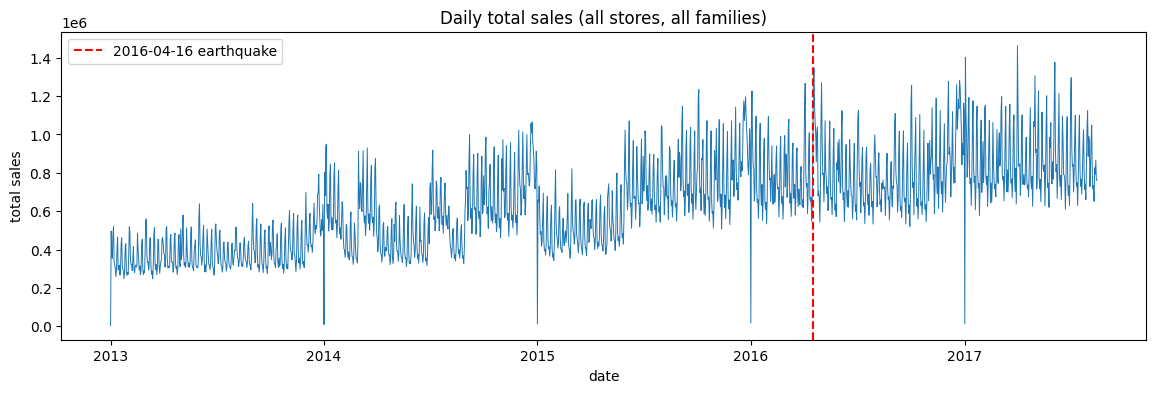

In [11]:
import matplotlib.pyplot as plt  # 그래프 도구, 관례적으로 plt라는 별명 사용

# 날짜별 전체 판매량 합계 (매장·상품군을 모두 더함)
daily_sales = train.groupby("date")["sales"].sum()
print("daily_sales 길이:", len(daily_sales))  # 날짜 수와 같아야 함 (1684)

fig, ax = plt.subplots(figsize=(14, 4))       # 가로 14, 세로 4 크기의 도화지
ax.plot(daily_sales.index, daily_sales.values, linewidth=0.7)

# 대회 설명에 나온 지진 날짜 표시
ax.axvline(pd.Timestamp("2016-04-16"), color="red", linestyle="--", label="2016-04-16 earthquake")

ax.set_title("Daily total sales (all stores, all families)")
ax.set_xlabel("date")
ax.set_ylabel("total sales")
ax.legend()
plt.show()

**그래프 1 해석**
- 장기적으로 판매량 상승 (2013년 약 40만 → 2017년 약 80만 이상) → 기준 모델은 최근 데이터만 사용
- 매년 1월 1일 근처 0에 가까운 값 → 휴무 추정
- 촘촘한 진동 → 요일 패턴 가능성 (그래프 2에서 확인)
- 계단식 상승 구간 → 기록 시작 시점 차이 가능성 (그래프 3에서 확인)

Mon     809438.0
Tue     751833.0
Wed     795493.0
Thu     667965.0
Fri     796294.0
Sat    1006766.0
Sun    1068859.0
Name: sales, dtype: float64


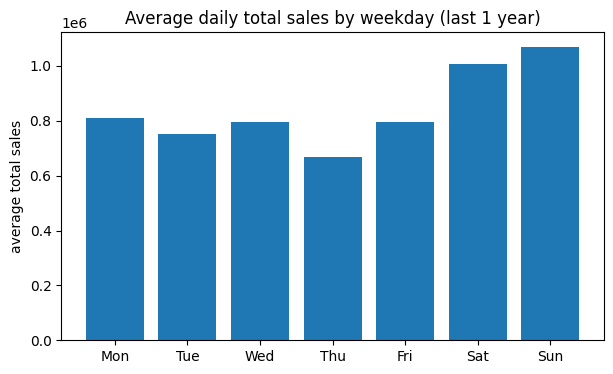

In [12]:
# 그래프 1에서 본 상승 추세의 영향을 줄이기 위해 최근 1년만 사용
recent_daily = daily_sales[daily_sales.index >= "2016-08-16"]

# 요일별 평균 (0=월 ~ 6=일)
weekday_mean = recent_daily.groupby(recent_daily.index.dayofweek).mean()
weekday_mean.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]  # 숫자 → 요일 이름
print(weekday_mean.round(0))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(weekday_mean.index, weekday_mean.values)
ax.set_title("Average daily total sales by weekday (last 1 year)")
ax.set_ylabel("average total sales")
plt.show()

In [13]:
# 가장 낮은 요일을 1로 놓았을 때 각 요일이 몇 배인지
print((weekday_mean / weekday_mean.min()).round(2))

Mon    1.21
Tue    1.13
Wed    1.19
Thu    1.00
Fri    1.19
Sat    1.51
Sun    1.60
Name: sales, dtype: float64


**그래프 2 해석**
- 최근 1년 기준, 주말(토·일) 판매량이 평일보다 높음
- 가장 높은 요일: ___ / 가장 낮은 요일: ___ / 차이: 약 ___ 배
- → 기준 모델은 전체 평균이 아니라 "같은 요일 평균"을 사용
- 참고: `.dayofweek`는 월=0 ~ 일=6

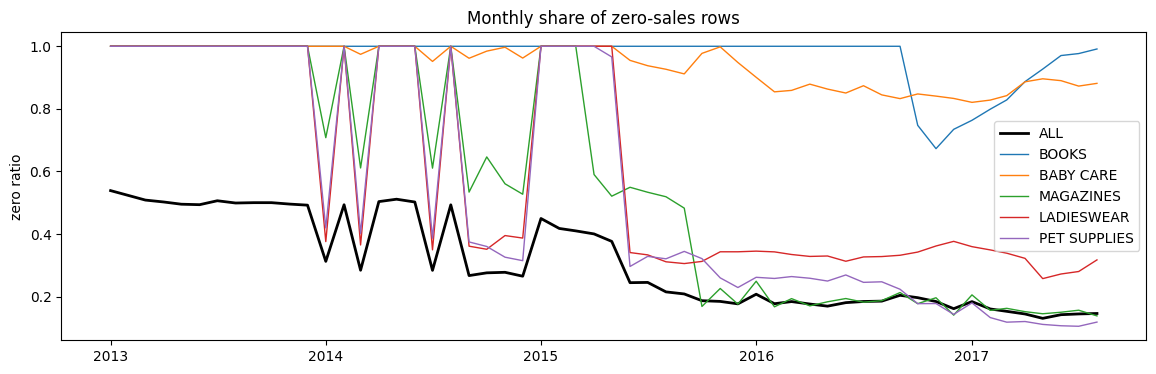

In [14]:
is_zero = train["sales"] == 0               # 1일차에 만든 것과 같음 (안전하게 다시 생성)
month = train["date"].dt.to_period("M")     # 각 행의 연-월

fig, ax = plt.subplots(figsize=(14, 4))

# 전체 월별 0 비율 (굵은 검은 선)
overall = is_zero.groupby(month).mean()
ax.plot(overall.index.to_timestamp(), overall.values, color="black", linewidth=2, label="ALL")

# 1일차에 0 비율이 높았던 상품군들
for fam in ["BOOKS", "BABY CARE", "MAGAZINES", "LADIESWEAR", "PET SUPPLIES"]:
    mask = train["family"] == fam           # 이 상품군 행만 True
    fam_ratio = is_zero[mask].groupby(month[mask]).mean()
    ax.plot(fam_ratio.index.to_timestamp(), fam_ratio.values, linewidth=1, label=fam)

ax.set_title("Monthly share of zero-sales rows")
ax.set_ylabel("zero ratio")
ax.legend()
plt.show()

**그래프 3 해석**
- 전체 0 비율: 2015년 중반 이전 약 50% → 이후 약 15~20%로 감소 후 안정
- MAGAZINES, LADIESWEAR, PET SUPPLIES: 2013년 기록 없음(0 비율 100%), 2014년 월별로 들쭉날쭉, 2015년 중반 이후 안정
  → 초기의 0은 "안 팔림"보다 "기록 안 됨"일 가능성 (1일차 가설 B 대체로 지지)
- BOOKS: 2016년 후반 잠깐 판매 후 2017년 다시 거의 0 / BABY CARE: 꾸준히 0 비율 높음 (가설 C)
- → 6일차 실험 후보: 2015년 중반 이후 데이터만으로 학습

판매량 상위 5개:
family
DAIRY         916.9
CLEANING     1230.7
PRODUCE      2334.3
BEVERAGES    3464.9
GROCERY I    4619.7
Name: sales, dtype: float64

판매량 하위 5개:
family
BABY CARE          0.25
BOOKS              0.33
HOME APPLIANCES    0.44
HARDWARE           1.33
BEAUTY             5.54
Name: sales, dtype: float64


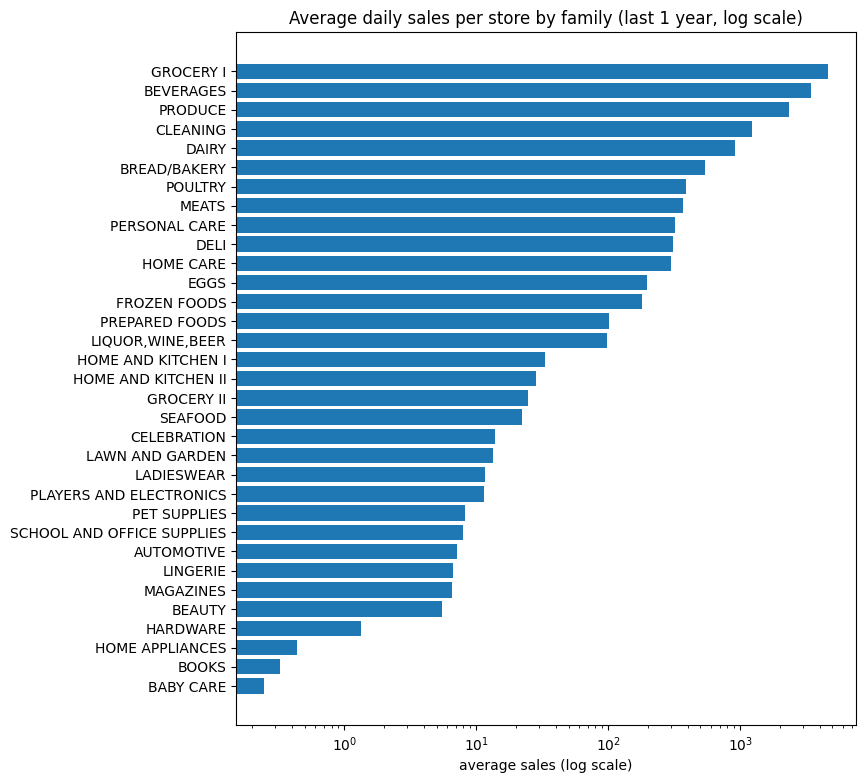

In [15]:
# 그래프 3 결과를 반영해, 기록이 안정된 최근 1년만 사용
recent = train[train["date"] >= "2016-08-16"]

# 상품군별 "매장 1곳의 하루 평균 판매량" (작은 값 → 큰 값 순)
family_mean = recent.groupby("family")["sales"].mean().sort_values()

print("판매량 상위 5개:")
print(family_mean.tail(5).round(1))
print("\n판매량 하위 5개:")
print(family_mean.head(5).round(2))

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(family_mean.index, family_mean.values)   # 가로 막대 (이름이 길어서)
ax.set_xscale("log")                              # x축을 로그 눈금으로
ax.set_title("Average daily sales per store by family (last 1 year, log scale)")
ax.set_xlabel("average sales (log scale)")
plt.show()

**그래프 4 해석**
- 최근 1년, 매장 1곳의 하루 평균 판매량: GROCERY I 4,619.7 ~ BABY CARE 0.25 (약 18,500배 차이)
- 하위: BABY CARE, BOOKS, HOME APPLIANCES, HARDWARE, BEAUTY (1일차 0 비율 높은 상품군과 일치)
- RMSLE는 "몇 배 틀렸나"로 오차를 재므로 판매량이 적은 상품군도 중요 → 4일차 log1p 변환 근거

최근 1년 중 프로모션 있는 행 비율: 43.8%
비교한 상품군 수: 32


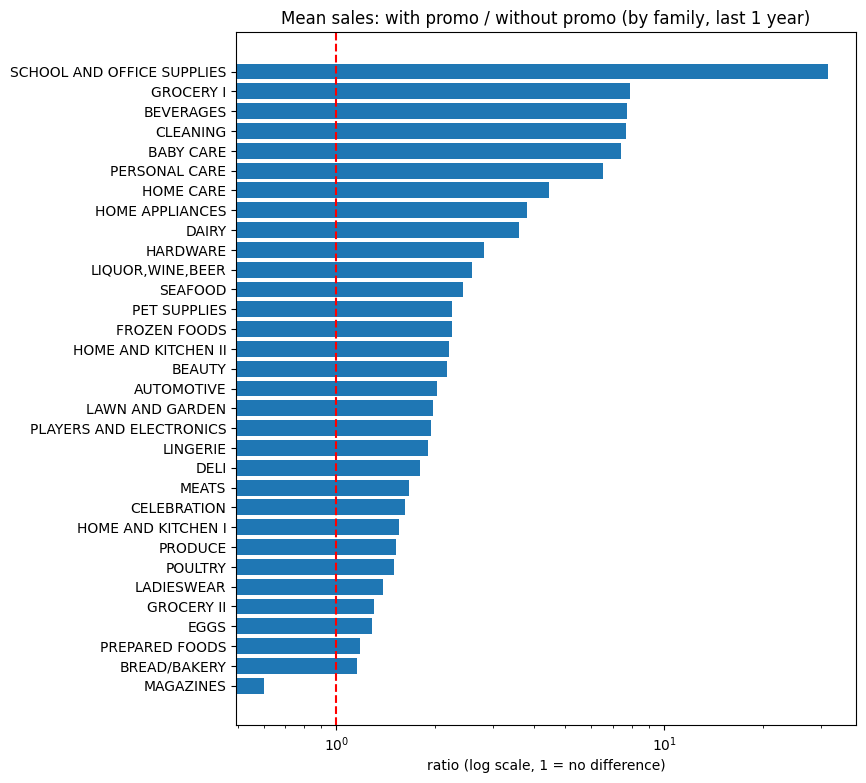

In [16]:
# 프로모션 중인 상품이 1개 이상인지 (True/False)
has_promo = (recent["onpromotion"] > 0).rename("has_promo")
print(f"최근 1년 중 프로모션 있는 행 비율: {has_promo.mean():.1%}")

# 상품군 × 프로모션 유무별 평균 판매량 → 프로모션 유무를 열로 펼침
promo_mean = recent.groupby([recent["family"], has_promo])["sales"].mean().unstack()

valid = promo_mean.dropna()          # 프로모션 있음/없음이 둘 다 있는 상품군만
valid = valid[valid[False] > 0]      # 0으로 나누는 경우 제외
ratio = (valid[True] / valid[False]).sort_values()
print("비교한 상품군 수:", len(ratio))

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(ratio.index, ratio.values)
ax.axvline(1, color="red", linestyle="--")   # 1배 = 차이 없음
ax.set_xscale("log")
ax.set_title("Mean sales: with promo / without promo (by family, last 1 year)")
ax.set_xlabel("ratio (log scale, 1 = no difference)")
plt.show()

**그래프 5 해석**
- 최근 1년, 32개 상품군 비교: 거의 모든 상품군에서 프로모션 있는 날 평균 판매량이 더 높음 (MAGAZINES만 예외)
- 최상위: SCHOOL AND OFFICE SUPPLIES(학용품·사무용품), 그다음 GROCERY I, BEVERAGES, CLEANING
- ⚠️ 관계일 뿐 원인은 아님: 학용품은 새 학기 시즌에 판매량과 프로모션이 함께 늘었을 가능성
- onpromotion은 test에 미리 주어지므로 4일차 모델 변수 후보
- 6일차 확인 후보: test 기간(8/16~31)이 새 학기 직전 → 학용품 과소 예측 위험

In [17]:
FORECAST_START = test["date"].min()   # 예측 시작일 (2017-08-16)
N_WEEKS = 4                           # 평균에 사용할 과거 주 수

# 예측 시작일 직전 N주 구간만 잘라내기
window_start = FORECAST_START - pd.Timedelta(weeks=N_WEEKS)
history = train[(train["date"] >= window_start) & (train["date"] < FORECAST_START)].copy()

print("사용 구간:", history["date"].min().date(), "~", history["date"].max().date())
print("날짜 수:", history["date"].nunique())

# 요일 열 추가 (0=월 ~ 6=일)
history["weekday"] = history["date"].dt.dayofweek

# 매장 × 상품군 × 요일별 평균 판매량
weekday_avg = (
    history.groupby(["store_nbr", "family", "weekday"])["sales"]
           .mean()
           .rename("pred_weekday")
           .reset_index()
)
print("평균표 크기:", weekday_avg.shape)
weekday_avg.head()

사용 구간: 2017-07-19 ~ 2017-08-15
날짜 수: 28
평균표 크기: (12474, 4)


,store_nbr,family,weekday,pred_weekday
0,1,AUTOMOTIVE,0,5.00
1,1,AUTOMOTIVE,1,5.75
2,1,AUTOMOTIVE,2,5.00
3,1,AUTOMOTIVE,3,5.25
4,1,AUTOMOTIVE,4,6.50


In [18]:
# test에 요일 열 추가 (train과 같은 방식)
test["weekday"] = test["date"].dt.dayofweek

# 공통 열(store_nbr, family, weekday) 기준으로 평균표를 test에 붙이기
submission_base = test.merge(weekday_avg, on=["store_nbr", "family", "weekday"], how="left")

print("merge 전 test 행 수:", len(test))
print("merge 후 행 수:", len(submission_base))
print("예측값이 없는(NaN) 행 수:", submission_base["pred_weekday"].isna().sum())

submission_base.head()

merge 전 test 행 수: 28512
merge 후 행 수: 28512
예측값이 없는(NaN) 행 수: 0


,id,date,store_nbr,family,onpromotion,weekday,pred_weekday
0,3000888,2017-08-16,1,AUTOMOTIVE,0,2,5.00
1,3000889,2017-08-16,1,BABY CARE,0,2,0.00
2,3000890,2017-08-16,1,BEAUTY,2,2,3.00
3,3000891,2017-08-16,1,BEVERAGES,20,2,2391.75
4,3000892,2017-08-16,1,BOOKS,0,2,0.00


In [19]:
sample_submission = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
print("sample_submission 열:", list(sample_submission.columns))

# 제출 형식에 맞게 열 이름 정리
submission = submission_base[["id", "pred_weekday"]].rename(columns={"pred_weekday": "sales"})
submission["sales"] = submission["sales"].clip(lower=0)   # 혹시 모를 음수 방지

# ===== 제출 전 점검 6가지 =====
print("\n[1] 열 이름 일치:", list(submission.columns) == list(sample_submission.columns))
print("[2] 행 수 일치:", len(submission) == len(test))
print("[3] id 완전 일치:", set(submission["id"]) == set(test["id"]))
print("[4] id 중복:", submission["id"].duplicated().sum(), "개")
print("[5] 결측치/무한대:", submission["sales"].isna().sum(), "/", 
      (~submission["sales"].apply(lambda x: x == x and abs(x) != float("inf"))).sum())
print("[6] 음수 개수:", (submission["sales"] < 0).sum())

submission.head()

sample_submission 열: ['id', 'sales']

[1] 열 이름 일치: True
[2] 행 수 일치: True
[3] id 완전 일치: True
[4] id 중복: 0 개
[5] 결측치/무한대: 0 / 0
[6] 음수 개수: 0


,id,sales
0,3000888,5.00
1,3000889,0.00
2,3000890,3.00
3,3000891,2391.75
4,3000892,0.00


In [20]:
submission.to_csv("submission.csv", index=False)
print("저장 완료. 행 수:", len(submission))

# 저장된 파일을 다시 읽어서 그대로인지 확인
check = pd.read_csv("submission.csv")
print(check.head())

저장 완료. 행 수: 28512
        id    sales
0  3000888     5.00
1  3000889     0.00
2  3000890     3.00
3  3000891  2391.75
4  3000892     0.00


### 실험 기록: Day2 - weekday baseline

- **실험 이름 / 날짜:** Day2 weekday baseline (4 weeks) / 2026-10-28
- **방법:** 예측 시작일(2017-08-16) 직전 4주, 매장×상품군×요일별 평균 판매량
- **학습(통계 계산)에 사용한 기간:** 2017-07-19 ~ 2017-08-15 (28일)
- **자체 검증 점수:** 아직 측정 안 함 (3일차에 시계열 검증 구성 후 계산 예정)
- **캐글 점수:** RMSLE 0.44491 (확인일: 2026-10-28)
- **해석:**
  - 첫 제출로 비교 기준선 확보. 아직 비교 대상이 없어 좋고 나쁨 판단 불가
  - 그래프 1~5의 패턴(최근 데이터 우선, 요일별, 상품군·매장별 분리)을 그대로 반영한 결과
- **다음 행동:** 3일차에 같은 방식으로 자체 검증(16일 구간)을 만들어, 캐글 점수와 별개로 내부에서 비교할 수 있는 기준을 마련한다

## 3일차 : 시계열 검증 체계

In [21]:
import numpy as np  # 숫자 계산 도구, 관례적으로 np라는 별명 사용

def rmsle(y_true, y_pred):
    """실제값(y_true)과 예측값(y_pred)으로 RMSLE 점수를 계산한다. 낮을수록 좋다."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    log_error = np.log1p(y_pred) - np.log1p(y_true)
    return np.sqrt(np.mean(log_error ** 2))

# ===== 작은 예시로 함수가 맞게 동작하는지 확인 (실제 데이터 아님) =====
example_true = [100, 10]
example_pred = [110, 20]
print("예시 RMSLE:", rmsle(example_true, example_pred))

예시 RMSLE: 0.4620821782653702


In [22]:
# 3개 구간의 시작일 · 종료일 (양 끝 포함)
FOLD1_START, FOLD1_END = pd.Timestamp("2017-06-29"), pd.Timestamp("2017-07-14")   # 개발 구간 1
FOLD2_START, FOLD2_END = pd.Timestamp("2017-07-15"), pd.Timestamp("2017-07-30")   # 개발 구간 2
HOLDOUT_START, HOLDOUT_END = pd.Timestamp("2017-07-31"), pd.Timestamp("2017-08-15")  # 최종 확인 (6일차 전용)

# ===== 설계가 맞는지 코드로 검증 =====
for name, start, end in [("Fold1", FOLD1_START, FOLD1_END),
                          ("Fold2", FOLD2_START, FOLD2_END),
                          ("Holdout", HOLDOUT_START, HOLDOUT_END)]:
    n_days = (end - start).days + 1
    print(f"{name}: {start.date()} ~ {end.date()} ({n_days}일)")

# 구간끼리 틈이나 겹침 없이 바로 이어지는지 확인
print("\nFold1 끝 다음날 = Fold2 시작일?", FOLD1_END + pd.Timedelta(days=1) == FOLD2_START)
print("Fold2 끝 다음날 = Holdout 시작일?", FOLD2_END + pd.Timedelta(days=1) == HOLDOUT_START)
print("Holdout 종료일 = train 마지막 날짜?", HOLDOUT_END == train["date"].max())

Fold1: 2017-06-29 ~ 2017-07-14 (16일)
Fold2: 2017-07-15 ~ 2017-07-30 (16일)
Holdout: 2017-07-31 ~ 2017-08-15 (16일)

Fold1 끝 다음날 = Fold2 시작일? True
Fold2 끝 다음날 = Holdout 시작일? True
Holdout 종료일 = train 마지막 날짜? True


In [23]:
def evaluate_weekday_baseline(data, forecast_start, forecast_end, n_weeks=4):
    """forecast_start 직전 n_weeks로 매장×상품군×요일 평균을 만들고,
    forecast_start~forecast_end 구간에서 RMSLE를 계산해 (점수, 상세표)를 돌려준다."""

    # ----- 2일차와 같은 방식: 과거 n_weeks로 평균표 만들기 -----
    window_start = forecast_start - pd.Timedelta(weeks=n_weeks)
    history = data[(data["date"] >= window_start) & (data["date"] < forecast_start)].copy()
    history["weekday"] = history["date"].dt.dayofweek

    weekday_avg = (
        history.groupby(["store_nbr", "family", "weekday"])["sales"]
               .mean()
               .rename("pred")
               .reset_index()
    )

    # ----- 채점할 구간: forecast_start ~ forecast_end의 "실제" 데이터 -----
    target = data[(data["date"] >= forecast_start) & (data["date"] <= forecast_end)].copy()
    target["weekday"] = target["date"].dt.dayofweek

    merged = target.merge(weekday_avg, on=["store_nbr", "family", "weekday"], how="left")
    merged["pred"] = merged["pred"].fillna(0).clip(lower=0)  # 혹시 모를 NaN·음수 방지

    score = rmsle(merged["sales"], merged["pred"])
    return score, merged


# ===== Fold1으로 먼저 테스트 =====
score1, detail1 = evaluate_weekday_baseline(train, FOLD1_START, FOLD1_END, n_weeks=4)
print("Fold1 RMSLE:", score1)
print("Fold1 대상 행 수:", len(detail1))
detail1.head()

Fold1 RMSLE: 0.42451530195097453
Fold1 대상 행 수: 28512


,id,date,store_nbr,family,sales,onpromotion,weekday,pred
0,2915352,2017-06-29,1,AUTOMOTIVE,1.0,0,3,2.75
1,2915353,2017-06-29,1,BABY CARE,0.0,0,3,0.00
2,2915354,2017-06-29,1,BEAUTY,2.0,1,3,4.50
3,2915355,2017-06-29,1,BEVERAGES,2128.0,26,3,2092.50
4,2915356,2017-06-29,1,BOOKS,0.0,0,3,1.00


In [24]:
results = []

for name, start, end in [("Fold1", FOLD1_START, FOLD1_END),
                          ("Fold2", FOLD2_START, FOLD2_END)]:
    score, _ = evaluate_weekday_baseline(train, start, end, n_weeks=4)
    results.append({"fold": name, "start": start.date(), "end": end.date(), "rmsle": score})

score_table = pd.DataFrame(results)
print(score_table)
print("\n평균 RMSLE:", score_table["rmsle"].mean())

    fold       start         end     rmsle
0  Fold1  2017-06-29  2017-07-14  0.424515
1  Fold2  2017-07-15  2017-07-30  0.442683

평균 RMSLE: 0.4335991126800987


### 검증 설계
- train 끝부분에서 연속 16일 구간 3개 (test와 동일 길이)
  - Fold1 (개발): 2017-06-29 ~ 07-14
  - Fold2 (개발): 2017-07-15 ~ 07-30
  - Holdout (최종 확인, 6일차 전용, 미사용): 2017-07-31 ~ 08-15
- 각 구간은 시작일 직전 4주로 만든 통계만 사용 (미래 정보 차단)
- 재사용 함수: `evaluate_weekday_baseline(data, forecast_start, forecast_end, n_weeks=4)`

### 기준 모델 구간별 RMSLE
| Fold | 기간 | RMSLE |
|---|---|---|
| Fold1 | 06-29~07-14 | 0.4245 |
| Fold2 | 07-15~07-30 | 0.4427 |
| **평균** | | **0.4336** |

- 캐글 실제 제출 점수(0.4449)와 약 0.011 차이 → 자체 검증이 실제 점수를 꽤 잘 대변함
- Holdout은 6일차까지 점수를 보지 않음 (반복 튜닝으로 인한 과적합 방지)

## 4일차 : LightGBM

In [25]:
import lightgbm as lgb
print("lightgbm 버전:", lgb.__version__)

# store_nbr, family의 "전체 목록"을 미리 고정해 둔다
# (학습용/예측용 어디서 만들어도 항상 같은 범주 목록을 쓰게 하기 위함)
STORE_CATEGORIES = sorted(train["store_nbr"].unique())
FAMILY_CATEGORIES = sorted(train["family"].unique())
STORE_DTYPE = pd.CategoricalDtype(categories=STORE_CATEGORIES)
FAMILY_DTYPE = pd.CategoricalDtype(categories=FAMILY_CATEGORIES)

print("매장 범주 수:", len(STORE_CATEGORIES))
print("상품군 범주 수:", len(FAMILY_CATEGORIES))


def build_features(df):
    """df(날짜·매장·상품군·onpromotion 포함)에서 LightGBM에 넣을 변수표를 만든다."""
    feat = pd.DataFrame({
        "store_nbr": df["store_nbr"].astype(STORE_DTYPE),
        "family": df["family"].astype(FAMILY_DTYPE),
        "onpromotion": df["onpromotion"],
        "year": df["date"].dt.year,
        "month": df["date"].dt.month,
        "day": df["date"].dt.day,
        "weekday": df["date"].dt.dayofweek,
    })
    return feat


# ===== 작은 예시로 확인: train 앞 3행으로 변수표 만들어보기 =====
sample_feat = build_features(train.head(3))
print(sample_feat)
print(sample_feat.dtypes)

lightgbm 버전: 4.6.0
매장 범주 수: 54
상품군 범주 수: 33
  store_nbr      family  onpromotion  year  month  day  weekday
0         1  AUTOMOTIVE            0  2013      1    1        1
1         1   BABY CARE            0  2013      1    1        1
2         1      BEAUTY            0  2013      1    1        1
store_nbr      category
family         category
onpromotion       int64
year              int32
month             int32
day               int32
weekday           int32
dtype: object


In [26]:
import time  # 학습 시간을 재기 위한 기본 도구

def evaluate_lightgbm(data, forecast_start, forecast_end, train_days=730, **lgb_params):
    """forecast_start 직전 train_days로 LightGBM을 학습하고,
    forecast_start~forecast_end 구간에서 RMSLE를 계산해 (점수, 상세표, 모델)을 돌려준다."""

    window_start = forecast_start - pd.Timedelta(days=train_days)
    history = data[(data["date"] >= window_start) & (data["date"] < forecast_start)].copy()
    target = data[(data["date"] >= forecast_start) & (data["date"] <= forecast_end)].copy()

    X_train = build_features(history)
    y_train = np.log1p(history["sales"])   # 판매량을 log1p로 변환해서 학습
    X_target = build_features(target)

    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        random_state=42, verbose=-1, **lgb_params
    )

    start_time = time.time()
    model.fit(X_train, y_train, categorical_feature=["store_nbr", "family"])
    train_seconds = time.time() - start_time

    pred_log = model.predict(X_target)
    pred = np.expm1(pred_log)          # log1p의 역변환: 원래 판매량 단위로 되돌림
    pred = np.clip(pred, 0, None)      # 혹시 모를 음수 방지

    score = rmsle(target["sales"], pred)

    detail = target[["id", "date", "store_nbr", "family", "sales"]].copy()
    detail["pred"] = pred

    return score, detail, train_seconds


# ===== Fold1으로 먼저 테스트 =====
lgb_score1, lgb_detail1, lgb_time1 = evaluate_lightgbm(train, FOLD1_START, FOLD1_END)
print("Fold1 LightGBM RMSLE:", lgb_score1)
print("학습 시간(초):", round(lgb_time1, 1))
lgb_detail1.head()

Fold1 LightGBM RMSLE: 0.461218594099211
학습 시간(초): 18.2


,id,date,store_nbr,family,sales,pred
2915352,2915352,2017-06-29,1,AUTOMOTIVE,1.0,3.563620
2915353,2915353,2017-06-29,1,BABY CARE,0.0,0.064020
2915354,2915354,2017-06-29,1,BEAUTY,2.0,4.365585
2915355,2915355,2017-06-29,1,BEVERAGES,2128.0,1905.746899
2915356,2915356,2017-06-29,1,BOOKS,0.0,0.113662


In [27]:
comparison = []

# Fold1: 이미 계산해 둔 값 재사용 (다시 학습하지 않음)
base_score1, _ = evaluate_weekday_baseline(train, FOLD1_START, FOLD1_END, n_weeks=4)
comparison.append({"fold": "Fold1", "baseline_rmsle": base_score1,
                    "lightgbm_rmsle": lgb_score1, "lightgbm_time_sec": round(lgb_time1, 1)})

# Fold2: 새로 계산
base_score2, _ = evaluate_weekday_baseline(train, FOLD2_START, FOLD2_END, n_weeks=4)
lgb_score2, lgb_detail2, lgb_time2 = evaluate_lightgbm(train, FOLD2_START, FOLD2_END)
comparison.append({"fold": "Fold2", "baseline_rmsle": base_score2,
                    "lightgbm_rmsle": lgb_score2, "lightgbm_time_sec": round(lgb_time2, 1)})

comparison_table = pd.DataFrame(comparison)
comparison_table["diff (lgb - baseline)"] = comparison_table["lightgbm_rmsle"] - comparison_table["baseline_rmsle"]

print(comparison_table)
print("\n기준 모델 평균:", comparison_table["baseline_rmsle"].mean())
print("LightGBM 평균:", comparison_table["lightgbm_rmsle"].mean())

    fold  baseline_rmsle  lightgbm_rmsle  lightgbm_time_sec  \
0  Fold1        0.424515        0.461219               18.2   
1  Fold2        0.442683        0.462231               16.2   

   diff (lgb - baseline)  
0               0.036703  
1               0.019548  

기준 모델 평균: 0.4335991126800987
LightGBM 평균: 0.4617248251583834


In [28]:
def train_lightgbm(data, forecast_start, train_days=730, **lgb_params):
    """forecast_start 직전 train_days로 LightGBM을 학습해 모델을 돌려준다."""
    window_start = forecast_start - pd.Timedelta(days=train_days)
    history = data[(data["date"] >= window_start) & (data["date"] < forecast_start)].copy()

    X_train = build_features(history)
    y_train = np.log1p(history["sales"])

    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        random_state=42, verbose=-1, **lgb_params
    )
    model.fit(X_train, y_train, categorical_feature=["store_nbr", "family"])
    return model


def predict_lightgbm(model, df):
    """학습된 model로 df(정답 없어도 됨)를 예측해 판매량 배열을 돌려준다."""
    X = build_features(df)
    pred_log = model.predict(X)
    return np.clip(np.expm1(pred_log), 0, None)


# ===== 실제 test 예측 =====
TEST_START = test["date"].min()   # 2017-08-16
final_model = train_lightgbm(train, TEST_START, train_days=730)
test_pred = predict_lightgbm(final_model, test)

submission_lgb = test[["id"]].copy()
submission_lgb["sales"] = test_pred
print(submission_lgb.head())

        id        sales
0  3000888     3.604471
1  3000889     0.081835
2  3000890     5.031218
3  3000891  2018.274364
4  3000892     0.095193


In [29]:
submission_lgb["sales"] = submission_lgb["sales"].clip(lower=0)   # 안전장치 (이미 predict_lightgbm에서 처리했지만 재확인)

print("[1] 열 이름 일치:", list(submission_lgb.columns) == list(sample_submission.columns))
print("[2] 행 수 일치:", len(submission_lgb) == len(test))
print("[3] id 완전 일치:", set(submission_lgb["id"]) == set(test["id"]))
print("[4] id 중복:", submission_lgb["id"].duplicated().sum(), "개")
print("[5] 결측치:", submission_lgb["sales"].isna().sum())
print("[6] 음수 개수:", (submission_lgb["sales"] < 0).sum())

submission_lgb.to_csv("submission.csv", index=False)
print("\n저장 완료. 행 수:", len(submission_lgb))

[1] 열 이름 일치: True
[2] 행 수 일치: True
[3] id 완전 일치: True
[4] id 중복: 0 개
[5] 결측치: 0
[6] 음수 개수: 0

저장 완료. 행 수: 28512


### 실험 기록: Day4 - LightGBM basic features

- **실험 이름 / 날짜:** Day4 LightGBM basic (date/store/family/promo) / 2026-10-29
- **변수:** store_nbr, family (범주형), onpromotion, year, month, day, weekday
- **모델 설정:** n_estimators=300, learning_rate=0.05, num_leaves=31, log1p(sales) 타깃
- **학습에 사용한 기간:** 예측 시작일 직전 730일(약 2년)
- **자체 검증 (Fold1/Fold2/평균):**

| Fold | 기준 모델 | LightGBM | 차이 |
|---|---|---|---|
| Fold1 | 0.4245 | 0.4612 | +0.0367 |
| Fold2 | 0.4427 | 0.4622 | +0.0195 |
| 평균 | 0.4336 | 0.4617 | +0.0281 |

- **학습 시간:** 약 8.9초 (fold당)
- **해석:** 두 구간 모두 LightGBM이 기준 모델보다 나쁨(일관된 방향). 모델에게 "최근 판매 수준"을 직접 알려주는 변수가 없어, 기준 모델의 직접 평균 계산을 범주형 조합만으로 따라가지 못하는 것으로 추정
- **캐글 점수:** RMSLE 0.46731 (확인일: 2026-10-29) — 기준 모델(0.44491) 대비 +0.0224
- **검증 틀 신뢰도 확인:** 자체 검증 차이(+0.0281)와 실제 캐글 차이(+0.0224)가 방향·크기 모두 비슷함 → 3일차 검증 틀이 실제 결과를 잘 예측함
- **다음 행동:** 5일차에 과거 판매량 요약(최근 평균/합계 등) 변수를 추가해 격차가 줄어드는지 확인

## 5일차 : 변수 개선 실험

In [30]:
def add_sales_history_features(df, data, forecast_start):
    """df(예측 대상)에 forecast_start 이전 데이터로 계산한 과거 판매량 요약 변수를 붙여 돌려준다."""

    history = data[data["date"] < forecast_start].copy()   # 미래 정보 완전 차단
    history["weekday"] = history["date"].dt.dayofweek

    def window_mean(n_weeks, colname):
        window_start = forecast_start - pd.Timedelta(weeks=n_weeks)
        window = history[history["date"] >= window_start]
        return window.groupby(["store_nbr", "family"])["sales"].mean().rename(colname)

    stat_4w = window_mean(4, "recent_mean_4w")
    stat_8w = window_mean(8, "recent_mean_8w")
    stat_12w = window_mean(12, "recent_mean_12w")

    # 같은 요일만 모아서 평균 (최근 4주)
    dow_window = history[history["date"] >= forecast_start - pd.Timedelta(weeks=4)]
    stat_dow = (dow_window.groupby(["store_nbr", "family", "weekday"])["sales"]
                          .mean().rename("recent_mean_dow").reset_index())

    out = df.copy()
    out["weekday"] = out["date"].dt.dayofweek
    out = out.merge(stat_4w.reset_index(), on=["store_nbr", "family"], how="left")
    out = out.merge(stat_8w.reset_index(), on=["store_nbr", "family"], how="left")
    out = out.merge(stat_12w.reset_index(), on=["store_nbr", "family"], how="left")
    out = out.merge(stat_dow, on=["store_nbr", "family", "weekday"], how="left")

    new_cols = ["recent_mean_4w", "recent_mean_8w", "recent_mean_12w", "recent_mean_dow"]
    out[new_cols] = out[new_cols].fillna(0)   # 해당 조합의 과거 기록이 없으면 0

    return out


# ===== Fold1로 테스트: 변수가 잘 붙는지 확인 =====
fold1_target = train[(train["date"] >= FOLD1_START) & (train["date"] <= FOLD1_END)]
enriched = add_sales_history_features(fold1_target, train, FOLD1_START)
print("원래 열 수:", fold1_target.shape[1], "→ 변수 추가 후 열 수:", enriched.shape[1])
enriched[["date", "store_nbr", "family", "sales",
          "recent_mean_4w", "recent_mean_8w", "recent_mean_12w", "recent_mean_dow"]].head(10)

원래 열 수: 6 → 변수 추가 후 열 수: 11


,date,store_nbr,family,sales,recent_mean_4w,recent_mean_8w,recent_mean_12w,recent_mean_dow
0,2017-06-29,1,AUTOMOTIVE,1.000000,4.500000,4.053571,4.035714,2.7500
1,2017-06-29,1,BABY CARE,0.000000,0.000000,0.000000,0.000000,0.0000
2,2017-06-29,1,BEAUTY,2.000000,3.500000,3.357143,3.130952,4.5000
3,2017-06-29,1,BEVERAGES,2128.000000,2285.821429,2192.803571,2156.119048,2092.5000
4,2017-06-29,1,BOOKS,0.000000,0.535714,0.446429,0.428571,1.0000
5,2017-06-29,1,BREAD/BAKERY,387.057000,361.640321,360.608018,355.326083,366.6185
6,2017-06-29,1,CELEBRATION,14.000000,16.464286,15.660714,15.750000,24.5000
7,2017-06-29,1,CLEANING,709.000000,666.678571,664.821429,653.464286,695.2500
8,2017-06-29,1,DAIRY,680.000000,721.035714,720.928571,718.654762,743.2500
9,2017-06-29,1,DELI,110.423996,133.399821,131.710839,130.907940,121.4545


In [31]:
def add_rolling_sales_features(data):
    """data의 각 행마다, '그 날짜 이전'의 정보로만 과거 판매량 요약 변수 4개를 계산해 붙인다."""
    df = data.sort_values(["store_nbr", "family", "date"]).copy()

    g = df.groupby(["store_nbr", "family"])["sales"]
    df["recent_mean_4w"]  = g.transform(lambda s: s.shift(1).rolling(28, min_periods=1).mean())
    df["recent_mean_8w"]  = g.transform(lambda s: s.shift(1).rolling(56, min_periods=1).mean())
    df["recent_mean_12w"] = g.transform(lambda s: s.shift(1).rolling(84, min_periods=1).mean())

    gd = df.groupby(["store_nbr", "family", df["date"].dt.dayofweek])["sales"]
    df["recent_mean_dow"] = gd.transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())

    stat_cols = ["recent_mean_4w", "recent_mean_8w", "recent_mean_12w", "recent_mean_dow"]
    df[stat_cols] = df[stat_cols].fillna(0)   # 맨 처음 행들(과거 기록 전혀 없음)은 0

    return df


train_rolled = add_rolling_sales_features(train)
print("train_rolled 행 수:", len(train_rolled), "(원래 train과 같아야 함:", len(train), ")")

# 매장1 AUTOMOTIVE의 한 구간만 눈으로 확인
check = train_rolled[(train_rolled["store_nbr"] == 1) & (train_rolled["family"] == "AUTOMOTIVE")]
check[["date", "sales", "recent_mean_4w", "recent_mean_dow"]].tail(10)

train_rolled 행 수: 3000888 (원래 train과 같아야 함: 3000888 )


,date,sales,recent_mean_4w,recent_mean_dow
2983068,2017-08-06,6.0,5.000000,1.25
2984850,2017-08-07,7.0,5.142857,4.25
2986632,2017-08-08,4.0,5.285714,6.25
2988414,2017-08-09,7.0,5.178571,5.00
2990196,2017-08-10,9.0,5.178571,5.25
2991978,2017-08-11,1.0,5.178571,7.25
2993760,2017-08-12,6.0,5.071429,5.75
2995542,2017-08-13,1.0,5.071429,2.25
2997324,2017-08-14,1.0,5.035714,5.25
2999106,2017-08-15,4.0,5.000000,5.50


In [32]:
def build_features_v2(df):
    """build_features()에 과거 판매량 요약 변수 4개를 추가로 붙인다."""
    feat = build_features(df)
    for col in ["recent_mean_4w", "recent_mean_8w", "recent_mean_12w", "recent_mean_dow"]:
        feat[col] = df[col].values
    return feat


def evaluate_lightgbm_v2(data_rolled, forecast_start, forecast_end, train_days=730, **lgb_params):
    """요약 변수를 포함해 LightGBM을 학습·평가한다."""
    window_start = forecast_start - pd.Timedelta(days=train_days)

    # 학습용: train_rolled의 행별(날짜별) 요약 변수를 그대로 사용
    history = data_rolled[(data_rolled["date"] >= window_start) & (data_rolled["date"] < forecast_start)].copy()

    # 예측 대상(16일): forecast_start 기준으로 '고정된' 요약 변수를 새로 계산해 붙임
    raw_target = data_rolled[(data_rolled["date"] >= forecast_start) & (data_rolled["date"] <= forecast_end)]
    raw_target = raw_target[["id", "date", "store_nbr", "family", "sales", "onpromotion"]].copy()
    target = add_sales_history_features(raw_target, train, forecast_start)

    X_train = build_features_v2(history)
    y_train = np.log1p(history["sales"])
    X_target = build_features_v2(target)

    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        random_state=42, verbose=-1, **lgb_params
    )
    model.fit(X_train, y_train, categorical_feature=["store_nbr", "family"])

    pred = np.clip(np.expm1(model.predict(X_target)), 0, None)
    score = rmsle(target["sales"], pred)

    detail = target[["id", "date", "store_nbr", "family", "sales"]].copy()
    detail["pred"] = pred
    return score, detail


# ===== Fold1, Fold2 비교 =====
exp1 = []
for name, start, end in [("Fold1", FOLD1_START, FOLD1_END), ("Fold2", FOLD2_START, FOLD2_END)]:
    score, _ = evaluate_lightgbm_v2(train_rolled, start, end)
    exp1.append({"fold": name, "lightgbm_v2_rmsle": score})

exp1_table = pd.DataFrame(exp1)
print(exp1_table)
print("\nLightGBM(v2) 평균:", exp1_table["lightgbm_v2_rmsle"].mean())
print("--- 비교 ---")
print("기준 모델 평균:        0.4336")
print("LightGBM 기본(4일차) 평균: 0.4617")

    fold  lightgbm_v2_rmsle
0  Fold1           0.381397
1  Fold2           0.395195

LightGBM(v2) 평균: 0.38829585373704434
--- 비교 ---
기준 모델 평균:        0.4336
LightGBM 기본(4일차) 평균: 0.4617


### 실험 기록: Day5 - 실험 1 (과거 판매량 요약 변수)

- **실험 이름 / 날짜:** Day5 Exp1 - sales history features (recent_mean 4w/8w/12w/dow) / 2026-10-30
- **추가한 변수:** recent_mean_4w, recent_mean_8w, recent_mean_12w, recent_mean_dow
  - 학습 데이터: 행별(날짜별) rolling 계산, shift(1)로 당일 값 제외 (누출 없음)
  - 예측 대상(16일): forecast_start 기준 고정 통계 (기준 모델과 동일 원리, 누출 방지)
- **학습에 사용한 기간:** 예측 시작일 직전 730일 (4일차와 동일)
- **자체 검증 (Fold1/Fold2/평균):**

| 방법 | Fold1 | Fold2 | 평균 |
|---|---|---|---|
| 기준 모델 | 0.4245 | 0.4427 | 0.4336 |
| LightGBM 기본(4일차) | 0.4612 | 0.4622 | 0.4617 |
| LightGBM + 과거 판매량 요약 | 0.3814 | 0.3952 | 0.3883 |

- **해석:** 4일차 가설이 맞았음. "최근 판매 수준" 정보를 직접 변수로 주자 LightGBM이 기준 모델을 약 10% 앞섬. 두 구간 모두 일관되게 개선 → 재현성 있는 결과
- **다음 행동:** 매장 특성(stores.csv), 휴일 정보를 추가로 넣었을 때 더 개선되는지 실험

In [33]:
stores = pd.read_csv(f"{DATA_DIR}/stores.csv")
print(stores.shape)
stores.head()

(54, 5)


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [34]:
CITY_DTYPE = pd.CategoricalDtype(categories=sorted(stores["city"].unique()))
STATE_DTYPE = pd.CategoricalDtype(categories=sorted(stores["state"].unique()))
TYPE_DTYPE = pd.CategoricalDtype(categories=sorted(stores["type"].unique()))
CLUSTER_DTYPE = pd.CategoricalDtype(categories=sorted(stores["cluster"].unique()))


def build_features_v3(df):
    """build_features_v2에 매장 특성(도시·주·유형·클러스터)을 추가로 붙인다."""
    feat = build_features_v2(df)
    store_info = df[["store_nbr"]].merge(stores, on="store_nbr", how="left")
    feat["city"] = store_info["city"].astype(CITY_DTYPE).values
    feat["state"] = store_info["state"].astype(STATE_DTYPE).values
    feat["type"] = store_info["type"].astype(TYPE_DTYPE).values
    feat["cluster"] = store_info["cluster"].astype(CLUSTER_DTYPE).values
    return feat


def evaluate_lightgbm_v3(data_rolled, forecast_start, forecast_end, train_days=730, **lgb_params):
    window_start = forecast_start - pd.Timedelta(days=train_days)
    history = data_rolled[(data_rolled["date"] >= window_start) & (data_rolled["date"] < forecast_start)].copy()

    raw_target = data_rolled[(data_rolled["date"] >= forecast_start) & (data_rolled["date"] <= forecast_end)]
    raw_target = raw_target[["id", "date", "store_nbr", "family", "sales", "onpromotion"]].copy()
    target = add_sales_history_features(raw_target, train, forecast_start)

    X_train = build_features_v3(history)
    y_train = np.log1p(history["sales"])
    X_target = build_features_v3(target)

    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        random_state=42, verbose=-1, **lgb_params
    )
    model.fit(X_train, y_train,
               categorical_feature=["store_nbr", "family", "city", "state", "type", "cluster"])

    pred = np.clip(np.expm1(model.predict(X_target)), 0, None)
    score = rmsle(target["sales"], pred)
    detail = target[["id", "date", "store_nbr", "family", "sales"]].copy()
    detail["pred"] = pred
    return score, detail


exp2 = []
for name, start, end in [("Fold1", FOLD1_START, FOLD1_END), ("Fold2", FOLD2_START, FOLD2_END)]:
    score, _ = evaluate_lightgbm_v3(train_rolled, start, end)
    exp2.append({"fold": name, "lightgbm_v3_rmsle": score})

exp2_table = pd.DataFrame(exp2)
print(exp2_table)
print("\nLightGBM(v3, +매장특성) 평균:", exp2_table["lightgbm_v3_rmsle"].mean())
print("LightGBM(v2, 과거판매량만) 평균: 0.38829585")

    fold  lightgbm_v3_rmsle
0  Fold1           0.386223
1  Fold2           0.395402

LightGBM(v3, +매장특성) 평균: 0.3908124899379406
LightGBM(v2, 과거판매량만) 평균: 0.38829585


### 실험 기록: Day5 - 실험 2 (매장 특성)

- **실험 이름 / 날짜:** Day5 Exp2 - store characteristics (city/state/type/cluster) / 2026-10-30
- **추가한 변수:** city, state, type, cluster (stores.csv, 범주형, 시간 불변이라 merge만으로 충분)
- **자체 검증 (Fold1/Fold2/평균):**

| 방법 | Fold1 | Fold2 | 평균 |
|---|---|---|---|
| 실험 1 (과거 판매량 요약) | 0.3814 | 0.3952 | 0.3883 |
| 실험 2 (+ 매장 특성) | 0.3862 | 0.3954 | 0.3908 |

- **해석:** 개선 없음(오히려 +0.0025 소폭 악화). city/state/type/cluster는 store_nbr로부터 결정되는 중복 정보라, 이미 store_nbr을 가진 모델에 새로운 정보를 주지 못함. train/test가 같은 54개 매장이라 "낯선 매장 일반화" 효과도 발휘되지 않음
- **다음 행동:** 매장 특성은 채택하지 않음(실험 1 구성 유지). 휴일 정보로 실험 3 진행

In [35]:
holidays = pd.read_csv(f"{DATA_DIR}/holidays_events.csv", parse_dates=["date"])
print(holidays.shape)
print(holidays["type"].value_counts())
print(holidays["locale"].value_counts())
holidays.head()

(350, 6)
type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [36]:
# "실제로 쉬는 날"만 남기기: 대체된(transferred=True) Holiday는 제외, Work Day·Event는 제외
real_holidays = holidays[
    holidays["type"].isin(["Holiday", "Additional", "Bridge", "Transfer"]) &
    ~((holidays["type"] == "Holiday") & (holidays["transferred"] == True))
].copy()

national_df = real_holidays[real_holidays["locale"] == "National"][["date"]].drop_duplicates()
national_df["is_national_holiday"] = 1

regional_df = (real_holidays[real_holidays["locale"] == "Regional"][["date", "locale_name"]]
               .drop_duplicates().rename(columns={"locale_name": "state"}))
regional_df["is_regional_holiday"] = 1

local_df = (real_holidays[real_holidays["locale"] == "Local"][["date", "locale_name"]]
            .drop_duplicates().rename(columns={"locale_name": "city"}))
local_df["is_local_holiday"] = 1


def compute_is_holiday(df):
    """df(date, store_nbr 포함)의 각 행이 그 매장 기준으로 휴일인지 0/1로 계산한다."""
    tmp = df[["date", "store_nbr"]].copy()
    store_info = tmp[["store_nbr"]].merge(stores, on="store_nbr", how="left")
    tmp["city"] = store_info["city"].values
    tmp["state"] = store_info["state"].values

    tmp = tmp.merge(national_df, on="date", how="left")
    tmp = tmp.merge(regional_df, on=["date", "state"], how="left")
    tmp = tmp.merge(local_df, on=["date", "city"], how="left")

    flags = tmp[["is_national_holiday", "is_regional_holiday", "is_local_holiday"]].fillna(0)
    is_holiday = (flags.sum(axis=1) > 0).astype(int)
    return is_holiday

def build_features_v4(df):
    """build_features_v2(과거 판매량 요약까지)에 휴일 여부를 추가로 붙인다."""
    feat = build_features_v2(df)
    feat["is_holiday"] = compute_is_holiday(df).values
    return feat


def build_features_v4(df):
    """build_features_v2(과거 판매량 요약까지)에 휴일 여부를 추가로 붙인다."""
    feat = build_features_v2(df)
    feat["is_holiday"] = compute_is_holiday(df).values
    return feat


# ===== 빠르게 확인: 2016-04-16(지진) 근처는 휴일로 안 잡히는지 등 =====
sample_check = train[train["date"] == "2017-01-01"].head(3)
print(compute_is_holiday(sample_check))

0    0
1    0
2    0
dtype: int64


In [37]:
# 원인 진단 1: 2017-01-01이 holidays 표에 실제로 있는지
print(holidays[holidays["date"] == "2017-01-01"])

# 원인 진단 2: transferred 열의 자료형과 실제 값들
print("\ntransferred 자료형:", holidays["transferred"].dtype)
print(holidays["transferred"].unique())

          date     type    locale locale_name         description  transferred
297 2017-01-01  Holiday  National     Ecuador  Primer dia del ano         True

transferred 자료형: bool
[False  True]


In [38]:
print(real_holidays[real_holidays["locale"] == "National"].head())

test_date = real_holidays[real_holidays["locale"] == "National"]["date"].iloc[0]
print("\n테스트 날짜:", test_date.date())

sample_check2 = train[train["date"] == test_date].head(3)
print(compute_is_holiday(sample_check2))

         date        type    locale locale_name  \
14 2012-08-10     Holiday  National     Ecuador   
20 2012-10-12    Transfer  National     Ecuador   
21 2012-11-02     Holiday  National     Ecuador   
22 2012-11-03     Holiday  National     Ecuador   
31 2012-12-21  Additional  National     Ecuador   

                            description  transferred  
14        Primer Grito de Independencia        False  
20  Traslado Independencia de Guayaquil        False  
21                      Dia de Difuntos        False  
22              Independencia de Cuenca        False  
31                            Navidad-4        False  

테스트 날짜: 2012-08-10
Series([], dtype: int64)


In [39]:
in_train_range = real_holidays[
    (real_holidays["locale"] == "National") &
    (real_holidays["date"] >= train["date"].min()) &
    (real_holidays["date"] <= train["date"].max())
]

test_date = in_train_range["date"].iloc[0]
print("테스트 날짜:", test_date.date())

sample_check2 = train[train["date"] == test_date].head(3)
print(compute_is_holiday(sample_check2))

테스트 날짜: 2013-01-01
0    1
1    1
2    1
dtype: int64


In [40]:
def evaluate_lightgbm_v2(data_rolled, forecast_start, forecast_end, train_days=730, **lgb_params):
    """요약 변수를 포함해 LightGBM을 학습·평가한다."""
    window_start = forecast_start - pd.Timedelta(days=train_days)
    history = data_rolled[(data_rolled["date"] >= window_start) & (data_rolled["date"] < forecast_start)].copy()
    target = data_rolled[(data_rolled["date"] >= forecast_start) & (data_rolled["date"] <= forecast_end)]
    target = target[["id", "date", "store_nbr", "family", "sales", "onpromotion"]].copy()
    target = add_sales_history_features(target, train, forecast_start)

    X_train = build_features_v2(history)
    y_train = np.log1p(history["sales"])
    X_target = build_features_v2(target)

    params = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1)
    params.update(lgb_params)   # 전달된 값으로 기본값을 덮어씀
    model = lgb.LGBMRegressor(**params)
    model.fit(X_train, y_train, categorical_feature=["store_nbr", "family"])

    pred = np.clip(np.expm1(model.predict(X_target)), 0, None)
    score = rmsle(target["sales"], pred)
    detail = target[["id", "date", "store_nbr", "family", "sales"]].copy()
    detail["pred"] = pred
    return score, detail

In [41]:
print("Fold1 구간 휴일:")
print(real_holidays[(real_holidays["date"] >= FOLD1_START) & (real_holidays["date"] <= FOLD1_END)])

print("\nFold2 구간 휴일:")
print(real_holidays[(real_holidays["date"] >= FOLD2_START) & (real_holidays["date"] <= FOLD2_END)])

Fold1 구간 휴일:
          date     type locale    locale_name                 description  \
318 2017-07-03  Holiday  Local      El Carmen  Cantonizacion de El Carmen   
319 2017-07-03  Holiday  Local  Santo Domingo  Fundacion de Santo Domingo   

     transferred  
318        False  
319        False  

Fold2 구간 휴일:
          date        type locale locale_name               description  \
320 2017-07-23     Holiday  Local     Cayambe  Cantonizacion de Cayambe   
321 2017-07-24  Additional  Local   Guayaquil  Fundacion de Guayaquil-1   
322 2017-07-25  Additional  Local   Guayaquil    Fundacion de Guayaquil   

     transferred  
320        False  
321        False  
322        False  


In [42]:
print("stores의 도시 목록:", sorted(stores["city"].unique()))

for name, start, end in [("Fold1", FOLD1_START, FOLD1_END), ("Fold2", FOLD2_START, FOLD2_END)]:
    target = train[(train["date"] >= start) & (train["date"] <= end)][["date", "store_nbr"]].drop_duplicates()
    target["is_holiday"] = compute_is_holiday(target)
    print(f"{name}: 휴일로 표시된 (날짜,매장) 조합 수 = {target['is_holiday'].sum()} / 전체 {len(target)}")

stores의 도시 목록: ['Ambato', 'Babahoyo', 'Cayambe', 'Cuenca', 'Daule', 'El Carmen', 'Esmeraldas', 'Guaranda', 'Guayaquil', 'Ibarra', 'Latacunga', 'Libertad', 'Loja', 'Machala', 'Manta', 'Playas', 'Puyo', 'Quevedo', 'Quito', 'Riobamba', 'Salinas', 'Santo Domingo']
Fold1: 휴일로 표시된 (날짜,매장) 조합 수 = 0.0 / 전체 864
Fold2: 휴일로 표시된 (날짜,매장) 조합 수 = 0.0 / 전체 864


In [43]:
print("local_df 행 수:", len(local_df))
print(local_df[local_df["city"].isin(["El Carmen", "Santo Domingo", "Cayambe", "Guayaquil"])])

print("\nstores에서 해당 도시:")
print(stores[stores["city"].isin(["El Carmen", "Santo Domingo", "Cayambe", "Guayaquil"])])

local_df 행 수: 147
          date           city  is_local_holiday
10  2012-07-03  Santo Domingo                 1
11  2012-07-03      El Carmen                 1
12  2012-07-23        Cayambe                 1
61  2013-07-03      El Carmen                 1
62  2013-07-03  Santo Domingo                 1
63  2013-07-23        Cayambe                 1
64  2013-07-24      Guayaquil                 1
65  2013-07-25      Guayaquil                 1
118 2014-07-03      El Carmen                 1
119 2014-07-03  Santo Domingo                 1
126 2014-07-23        Cayambe                 1
127 2014-07-24      Guayaquil                 1
128 2014-07-25      Guayaquil                 1
179 2015-07-03      El Carmen                 1
180 2015-07-03  Santo Domingo                 1
181 2015-07-23        Cayambe                 1
182 2015-07-24      Guayaquil                 1
183 2015-07-25      Guayaquil                 1
261 2016-07-03      El Carmen                 1
262 2016-07-03  Santo 

In [44]:
print("local_df의 date 자료형:", local_df["date"].dtype)
print("national_df의 date 자료형:", national_df["date"].dtype)
print("train의 date 자료형:", train["date"].dtype)

local_df의 date 자료형: datetime64[ns]
national_df의 date 자료형: datetime64[ns]
train의 date 자료형: datetime64[ns]


In [45]:
# 글자 뒤에 숨은 공백 등을 repr()로 드러내서 비교
print(repr(sorted(local_df["city"].unique())))
print(repr(sorted(stores["city"].unique())))

# local_df와 stores를 city 하나만으로 직접 merge 해보기 (단순화된 테스트)
test_merge = local_df.merge(stores[["store_nbr", "city"]], on="city", how="inner")
print("\n직접 merge 테스트 행 수:", len(test_merge))
test_merge.head()

['Ambato', 'Cayambe', 'Cuenca', 'El Carmen', 'Esmeraldas', 'Guaranda', 'Guayaquil', 'Ibarra', 'Latacunga', 'Libertad', 'Loja', 'Machala', 'Manta', 'Puyo', 'Quevedo', 'Quito', 'Riobamba', 'Salinas', 'Santo Domingo']
['Ambato', 'Babahoyo', 'Cayambe', 'Cuenca', 'Daule', 'El Carmen', 'Esmeraldas', 'Guaranda', 'Guayaquil', 'Ibarra', 'Latacunga', 'Libertad', 'Loja', 'Machala', 'Manta', 'Playas', 'Puyo', 'Quevedo', 'Quito', 'Riobamba', 'Salinas', 'Santo Domingo']

직접 merge 테스트 행 수: 474


,date,city,is_local_holiday,store_nbr
0,2012-03-02,Manta,1,52
1,2012-03-02,Manta,1,53
2,2012-04-12,Cuenca,1,37
3,2012-04-12,Cuenca,1,39
4,2012-04-12,Cuenca,1,42


In [46]:
target_dates = pd.to_datetime(["2017-07-03", "2017-07-23", "2017-07-24", "2017-07-25"])
print(test_merge[test_merge["date"].isin(target_dates)])

          date           city  is_local_holiday  store_nbr
404 2017-07-03      El Carmen                 1         54
405 2017-07-03  Santo Domingo                 1          5
406 2017-07-03  Santo Domingo                 1         16
407 2017-07-03  Santo Domingo                 1         21
408 2017-07-23        Cayambe                 1         11
409 2017-07-24      Guayaquil                 1         24
410 2017-07-24      Guayaquil                 1         26
411 2017-07-24      Guayaquil                 1         28
412 2017-07-24      Guayaquil                 1         29
413 2017-07-24      Guayaquil                 1         30
414 2017-07-24      Guayaquil                 1         32
415 2017-07-24      Guayaquil                 1         34
416 2017-07-24      Guayaquil                 1         51
417 2017-07-25      Guayaquil                 1         24
418 2017-07-25      Guayaquil                 1         26
419 2017-07-25      Guayaquil                 1         

In [47]:
for name, start, end in [("Fold1", FOLD1_START, FOLD1_END), ("Fold2", FOLD2_START, FOLD2_END)]:
    target = train[(train["date"] >= start) & (train["date"] <= end)][["date", "store_nbr"]].drop_duplicates()
    target["is_holiday"] = compute_is_holiday(target).values   # .values 추가
    print(f"{name}: 휴일로 표시된 (날짜,매장) 조합 수 = {target['is_holiday'].sum()} / 전체 {len(target)}")

Fold1: 휴일로 표시된 (날짜,매장) 조합 수 = 4 / 전체 864
Fold2: 휴일로 표시된 (날짜,매장) 조합 수 = 17 / 전체 864


### 실험 기록: Day5 - 실험 3 (휴일 정보)

- **실험 이름 / 날짜:** Day5 Exp3 - holiday feature (national/regional/local, transferred 처리) / 2026-10-31
- **추가한 변수:** is_holiday (0/1) — 전국/지역(주)/도시 범위를 구분하고, 대체된(transferred) 휴일은 제외, 실제 Transfer/Bridge/Additional은 포함
- **자체 검증 (Fold1/Fold2/평균):**

| 방법 | Fold1 | Fold2 | 평균 |
|---|---|---|---|
| 실험 1 (과거 판매량 요약) | 0.3814 | 0.3952 | 0.3883 |
| 실험 3 (+ 휴일) | 0.3814 | 0.3958 | 0.3886 |

- **해석:** 개선 거의 없음(오차 수준). 원인 확인 결과, Fold1은 864개 (날짜,매장) 조합 중 휴일이 4개, Fold2는 17개뿐 → 이번 두 검증 구간(6~7월)에는 휴일이 거의 없어 변수를 테스트할 표본 자체가 부족했음. "휴일이 쓸모없다"가 아니라 "이번 검증 구간이 적합하지 않았다"가 정확한 결론
- **디버깅 노트:** 함수가 내부에서 merge를 하면 인덱스가 리셋되는데, `df["열"] = 함수결과`로 바로 대입하면 인덱스가 안 맞아 값이 조용히 사라지는 버그 발견 → `.values`로 받아야 올바름. 실제 모델 학습 코드(`build_features_v4`)는 처음부터 `.values`를 썼기 때문에 이 버그의 영향을 받지 않았음
- **다음 행동:** 휴일 변수는 유지(손해는 없음). 6일차 오류 분석에서 휴일이 많은 시기(12월 등)가 포함된다면 재평가 고려

In [48]:
def train_lightgbm_v2(data_rolled, forecast_start, train_days=730, **lgb_params):
    """forecast_start 직전 train_days로, 과거 판매량 요약 변수까지 포함해 LightGBM을 학습한다."""
    window_start = forecast_start - pd.Timedelta(days=train_days)
    history = data_rolled[(data_rolled["date"] >= window_start) & (data_rolled["date"] < forecast_start)].copy()

    X_train = build_features_v2(history)
    y_train = np.log1p(history["sales"])

    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        random_state=42, verbose=-1, **lgb_params
    )
    model.fit(X_train, y_train, categorical_feature=["store_nbr", "family"])
    return model


def predict_lightgbm_v2(model, target_df):
    """학습된 model로 target_df(과거 판매량 요약 변수 포함)를 예측한다."""
    X = build_features_v2(target_df)
    pred_log = model.predict(X)
    return np.clip(np.expm1(pred_log), 0, None)

In [49]:
TEST_START = test["date"].min()   # 2017-08-16 (2·4일차와 동일한 변수)

# 1) 최종 모델 학습 (전체 학습 가능 기간 사용)
final_model_v2 = train_lightgbm_v2(train_rolled, TEST_START, train_days=730)

# 2) test에 과거 판매량 요약 변수를 '고정 통계'로 계산해 붙임
raw_test = test[["id", "date", "store_nbr", "family", "onpromotion"]].copy()
test_target = add_sales_history_features(raw_test, train, TEST_START)

# 3) 예측
test_pred_v2 = predict_lightgbm_v2(final_model_v2, test_target)

submission_v2 = test[["id"]].copy()
submission_v2["sales"] = test_pred_v2
print(submission_v2.head())

        id        sales
0  3000888     4.182967
1  3000889     0.056081
2  3000890     4.942923
3  3000891  2291.731906
4  3000892     0.114061


In [50]:
submission_v2["sales"] = submission_v2["sales"].clip(lower=0)

print("[1] 열 이름 일치:", list(submission_v2.columns) == list(sample_submission.columns))
print("[2] 행 수 일치:", len(submission_v2) == len(test))
print("[3] id 완전 일치:", set(submission_v2["id"]) == set(test["id"]))
print("[4] id 중복:", submission_v2["id"].duplicated().sum(), "개")
print("[5] 결측치:", submission_v2["sales"].isna().sum())
print("[6] 음수 개수:", (submission_v2["sales"] < 0).sum())

submission_v2.to_csv("submission.csv", index=False)
print("\n저장 완료. 행 수:", len(submission_v2))

[1] 열 이름 일치: True
[2] 행 수 일치: True
[3] id 완전 일치: True
[4] id 중복: 0 개
[5] 결측치: 0
[6] 음수 개수: 0

저장 완료. 행 수: 28512


### Day5 - 제출 결과 및 중요한 발견

- **제출:** Day5 LightGBM + sales history features / 2026-10-31
- **자체 검증 평균:** 0.3883 (기준 모델 0.4336보다 훨씬 좋음)
- **실제 캐글 점수:** RMSLE 0.46605 (확인일: 2026-10-31) — 기준 모델(0.44491)보다 오히려 나쁨
- **⚠️ 중요한 발견:** 오프라인-실제 점수 차이가 이 모델만 유독 큼 (0.078, 다른 모델은 0.006~0.011)
- **가설:** Fold1·Fold2(6~7월)와 실제 test(8월 중순, 새 학기 직전)의 계절이 달라서, "최근 평균"에 크게 의존하는 변수가 그 차이에 더 민감하게 반응한 것으로 추정. 2일차에 이미 "학용품 과소 예측 위험"을 경고했었음
- **다음 행동:** 6일차 오류 분석에서 **상품군별·날짜별 오차**를 확인해 이 가설을 검증. 특히 SCHOOL AND OFFICE SUPPLIES 등 계절성이 강한 상품군을 집중 확인

## 6일차 : 오류 분석과 모델 선택

In [51]:
# Fold1, Fold2의 실제값·예측값 상세 결과를 다시 계산해서 보관
score1, detail1 = evaluate_lightgbm_v2(train_rolled, FOLD1_START, FOLD1_END)
score2, detail2 = evaluate_lightgbm_v2(train_rolled, FOLD2_START, FOLD2_END)
print("Fold1:", score1, " Fold2:", score2)

detail_all = pd.concat([detail1, detail2], ignore_index=True)
print("합친 행 수:", len(detail_all))


def rmsle_by_group(df, group_col):
    """group_col 기준으로 묶어, 그룹마다 RMSLE를 계산해 나쁜 순서로 정렬한다."""
    result = df.groupby(group_col).apply(lambda g: rmsle(g["sales"], g["pred"]))
    return result.sort_values(ascending=False)


family_error = rmsle_by_group(detail_all, "family")
print("\n상품군별 RMSLE (나쁜 순서 상위 10개):")
print(family_error.head(10))

print("\nSCHOOL AND OFFICE SUPPLIES 순위:",
      list(family_error.index).index("SCHOOL AND OFFICE SUPPLIES") + 1, "/", len(family_error))
print("SCHOOL AND OFFICE SUPPLIES RMSLE:", family_error["SCHOOL AND OFFICE SUPPLIES"])

Fold1: 0.38139665998595085  Fold2: 0.3951950474881379
합친 행 수: 57024

상품군별 RMSLE (나쁜 순서 상위 10개):
family
LINGERIE                      0.618312
GROCERY II                    0.614898
CELEBRATION                   0.547114
LIQUOR,WINE,BEER              0.545600
SCHOOL AND OFFICE SUPPLIES    0.538778
HARDWARE                      0.525503
MAGAZINES                     0.513576
AUTOMOTIVE                    0.494370
SEAFOOD                       0.472311
LADIESWEAR                    0.471330
dtype: float64

SCHOOL AND OFFICE SUPPLIES 순위: 5 / 33
SCHOOL AND OFFICE SUPPLIES RMSLE: 0.538778109566602


/tmp/ipykernel_16/997016993.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result = df.groupby(group_col).apply(lambda g: rmsle(g["sales"], g["pred"]))


In [52]:
def bias_by_group(df, group_col):
    """group_col 기준으로 묶어, 평균적으로 과대(+)/과소(-) 예측했는지 계산한다."""
    result = df.groupby(group_col, group_keys=False).apply(
        lambda g: (g["pred"] - g["sales"]).mean(), include_groups=False
    )
    return result

family_bias = bias_by_group(detail_all, "family")

worst_10 = family_error.head(10).index
print("나쁜 상위 10개 상품군의 방향성 (양수=과대예측, 음수=과소예측):")
print(family_bias[worst_10].sort_values())

나쁜 상위 10개 상품군의 방향성 (양수=과대예측, 음수=과소예측):
family
GROCERY II                   -6.760905
LIQUOR,WINE,BEER             -5.841289
SCHOOL AND OFFICE SUPPLIES   -3.010232
SEAFOOD                      -1.822256
CELEBRATION                  -1.801343
LINGERIE                     -0.947856
LADIESWEAR                   -0.692949
AUTOMOTIVE                   -0.679264
MAGAZINES                    -0.663707
HARDWARE                     -0.383649
dtype: float64


In [53]:
# detail_all에는 onpromotion이 없으므로 train에서 가져와 붙임
detail_promo = detail_all.merge(train[["id", "onpromotion"]], on="id", how="left")
detail_promo["has_promo"] = detail_promo["onpromotion"] > 0
detail_promo["bias"] = detail_promo["pred"] - detail_promo["sales"]

print("전체 행 기준 (프로모션 유무별 평균 오차):")
print(detail_promo.groupby("has_promo")["bias"].mean())

print("\n나쁜 상위 10개 상품군만 (프로모션 유무별 평균 오차):")
worst_10 = family_error.head(10).index
worst_detail = detail_promo[detail_promo["family"].isin(worst_10)]
print(worst_detail.groupby("has_promo")["bias"].mean())

전체 행 기준 (프로모션 유무별 평균 오차):
has_promo
False   -1.671116
True    -7.072376
Name: bias, dtype: float64

나쁜 상위 10개 상품군만 (프로모션 유무별 평균 오차):
has_promo
False   -1.136576
True    -7.768654
Name: bias, dtype: float64


### Day6 - 오류 분석 결과

- **① 상품군별 오차:** SCHOOL AND OFFICE SUPPLIES는 5위(33개 중)로 나쁜 편이지만 1위는 아님. LINGERIE, GROCERY II가 더 나쁨 → "새 학기" 단일 원인이 아니라 더 넓은 패턴 존재
- **② 방향성:** 나쁜 상위 10개 상품군 **전부 과소예측**(일관된 방향)
- **③ 원인 규명:** 프로모션이 있을 때 과소예측이 **4~7배 더 심함** (전체 -1.67→-7.07, 상위10개 -1.14→-7.77)
- **결론:** 모델이 프로모션의 판매 상승 효과를 충분히 학습하지 못함 → 5일차의 "오프라인-실제 큰 차이"도 이것으로 일부 설명 가능 (8월에 프로모션이 더 많았다면 그 효과를 놓쳤을 것)

In [54]:
score1_b, detail1_b = evaluate_lightgbm_v2(train_rolled, FOLD1_START, FOLD1_END, num_leaves=63)
score2_b, detail2_b = evaluate_lightgbm_v2(train_rolled, FOLD2_START, FOLD2_END, num_leaves=63)

print("num_leaves=63  Fold1:", score1_b, " Fold2:", score2_b)
print("평균:", (score1_b + score2_b) / 2)
print("기존(num_leaves=31) 평균: 0.38829585")

# 프로모션 효과를 더 잘 배웠는지 확인
detail_b_all = pd.concat([detail1_b, detail2_b], ignore_index=True)
detail_b_promo = detail_b_all.merge(train[["id", "onpromotion"]], on="id", how="left")
detail_b_promo["has_promo"] = detail_b_promo["onpromotion"] > 0
detail_b_promo["bias"] = detail_b_promo["pred"] - detail_b_promo["sales"]
print("\n프로모션 유무별 평균 오차 (num_leaves=63):")
print(detail_b_promo.groupby("has_promo")["bias"].mean())

num_leaves=63  Fold1: 0.3815731733391998  Fold2: 0.3941955871591126
평균: 0.3878843802491562
기존(num_leaves=31) 평균: 0.38829585

프로모션 유무별 평균 오차 (num_leaves=63):
has_promo
False    -1.489059
True    -10.054861
Name: bias, dtype: float64


### Day6 - 설정 조정 시도

- **시도:** num_leaves 31 → 63 (프로모션 상호작용을 더 잘 학습시키려는 목적)
- **결과:** 전체 평균 거의 동일(0.3883 → 0.3879, 무시할 수준). 프로모션 과소예측은 오히려 악화(-7.07 → -10.05)
- **해석:** 나무 복잡도를 높이는 게 해결책이 아니었음. 데이터가 적은 조합(프로모션 날)에서 과적합 위험이 더 큼
- **결정:** num_leaves=31(기존 설정) 유지. 이 방향의 조정은 기각

In [55]:
score_holdout, detail_holdout = evaluate_lightgbm_v2(train_rolled, HOLDOUT_START, HOLDOUT_END)

print("Holdout RMSLE:", score_holdout)
print("\n--- 비교 ---")
print("Fold1:", 0.381397, " Fold2:", 0.395195, " 평균:", 0.38829585)
print("Holdout:", score_holdout)

# 기준 모델도 같은 구간에서 비교
base_holdout, _ = evaluate_weekday_baseline(train, HOLDOUT_START, HOLDOUT_END, n_weeks=4)
print("\n기준 모델 Holdout:", base_holdout)

Holdout RMSLE: 0.429122202722238

--- 비교 ---
Fold1: 0.381397  Fold2: 0.395195  평균: 0.38829585
Holdout: 0.429122202722238

기준 모델 Holdout: 0.531130405730008


### Day6 - 최종 모델 선정

**비교 요약**

| 구간 | 기준 모델 | LightGBM | 승자 |
|---|---|---|---|
| Fold1 | 0.4245 | 0.3814 | LightGBM |
| Fold2 | 0.4427 | 0.3952 | LightGBM |
| Holdout | 0.5311 | 0.4291 | LightGBM |
| 실제 캐글 | 0.4449 | 0.4661 | 기준 모델 |

**최종 선택: LightGBM + 과거 판매량 요약 (num_leaves=31, train_days=730)**

- 근거: 자체 검증(내부 3개 구간) 모두에서 일관되게 기준 모델보다 우수 (계획 원칙: "모델 선택은 자체 검증 중심, 캐글 점수는 외부 비교용")
- 알려진 위험: 실제 캐글 제출에서는 기준 모델에 뒤짐(0.4449 vs 0.4661). 원인으로 실제 test(8/16~31)와 검증 구간(6~8월 초) 간 계절 차이, 프로모션 효과 과소학습(6일차 오류 분석에서 확인)을 의심 중이나 완전히 규명되지 않음
- Holdout(0.5311)에서 기준 모델도 Fold 평균 대비 크게 악화 → Holdout 구간 자체가 변동성이 큰 예외적 시기일 가능성, 3개뿐인 검증 구간의 한계로 기록
- num_leaves=63 조정 시도는 효과 없어 기각 (31 유지)